-- 1. PROBLEM DEFINITION

Predicting client attrition for ConnectTel Telecom Company is the issue we hope to solve via data mining. Customer churn is the rate at which customers discontinue their relationship with a business over a given period, and in this case, it is when a customer cancels their phone or internet plan and switches to another provider. This is a serious risk to the longevity, expansion and growth of the company.

Implementing an effective customer churn prediction system can offer ConnectTel a range of strategic advantages:

Refined Retention Efforts: With the ability to pinpoint customers who are likely to leave, ConnectTel can design and deploy customized retention campaigns. Whether it's through exclusive offers, tailored messaging, or service enhancements, these proactive measures can significantly increase the chances of keeping high-value clients.

Efficient Resource Allocation: Rather than spreading retention efforts across the entire customer base, churn prediction enables a more focused approach. Resources can be directed toward individuals with a higher risk of leaving, ensuring that time and money are used where they’ll have the greatest impact.

Improved Service Delivery: Insights gained from churn data can highlight recurring issues or service gaps. By addressing these areas, ConnectTel can enhance the customer journey, leading to greater satisfaction and reduced churn over time.

Stronger Market Position: In a competitive telecom landscape, reducing churn not only protects revenue but also builds customer loyalty. Leveraging predictive analytics allows ConnectTel to maintain long-term relationships and establish a more resilient market presence.

In [40]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import warnings

In [41]:

df =  pd.read_csv("/Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [42]:
df.shape

(7043, 21)

In [43]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80


In [44]:
df.describe(include= 'object').T

,count,unique,top,freq
customerID,7043,7043,3186-AJIEK,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [46]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


a) Visualize relationships between the label and some key features

In the visualization below, the key features that will be understudied would be Senior Citizen, Partner, Dependents, Phoneservice, MultipleLines and Gender.

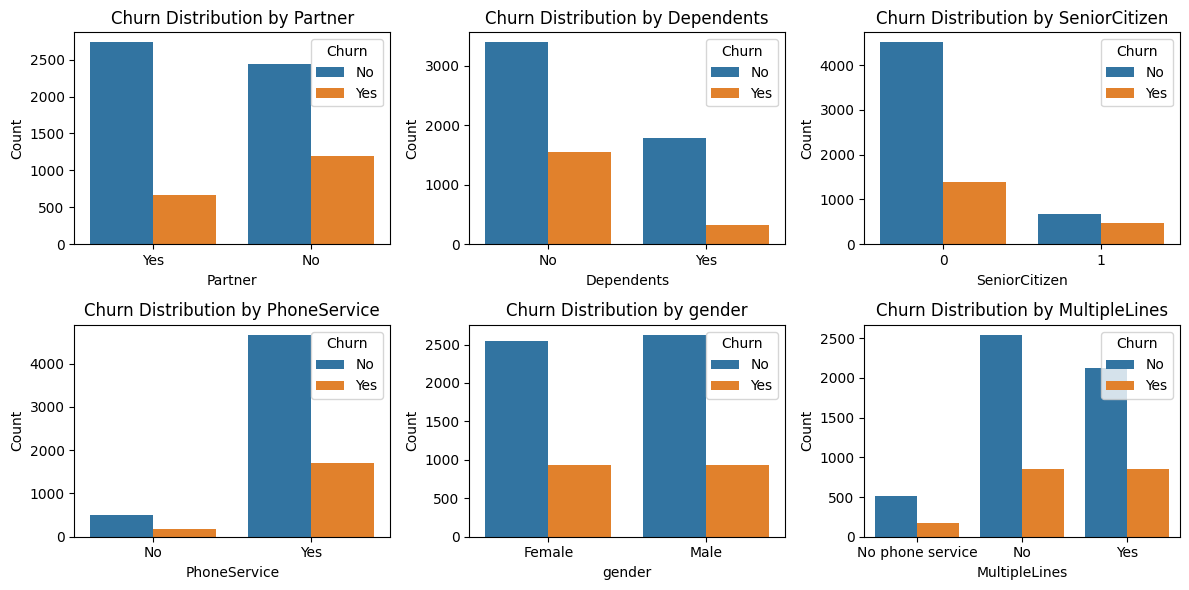

In [48]:
key_features = ['Partner', 'Dependents', 'SeniorCitizen', 'PhoneService', 'gender', 'MultipleLines']

# Visualizing key features using bar plots
plt.figure(figsize=(12, 6))
for i, feature in enumerate(key_features, 1):
    plt.subplot(2, 3, i)
    sns.countplot(x=feature, hue='Churn', data=df)
    plt.title(f'Churn Distribution by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Churn', loc='upper right')

plt.tight_layout()
plt.show();

(a) Customers with a partner churned at a much lower rate than those without a partner,this suggests that having a partner may be correlated with greater service stickiness.

(b) Customers without dependents had a substantially higher churn versus customers with dependents.

(c) Customers that are senior citizen churned at a much higher rate than non-senior citizens.

(d) Customers without Phone service churned at a lower rate compared to customers with Phone service.

(e) Regardless of the Gender, Females and males churn at nearly identical rates.

(f) Having multiple lines or none doesn’t drastically change churn, though multi‑line customers are slightly more likely to leave.

Overall, the biggest gaps in churn rates show up around partner status, dependents, and age, while gender and basic phone service levels have little effect.

<Figure size 800x600 with 0 Axes>

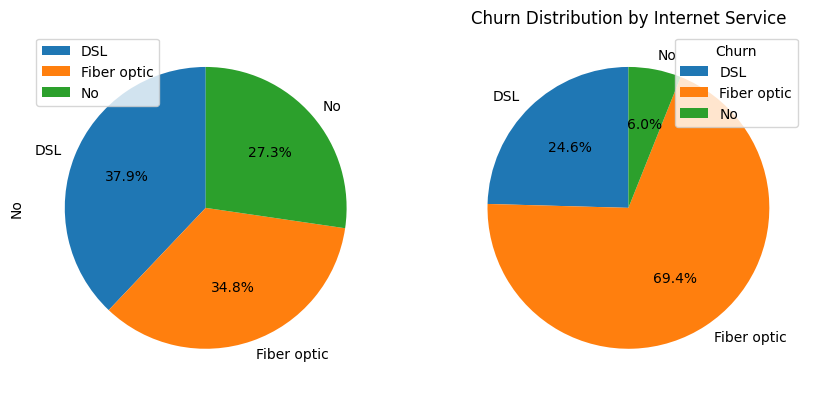

In [49]:
# Visualizing churn distribution with pie chart for InternetService
plt.figure(figsize=(8, 6))
internet_churn = df.groupby('InternetService')['Churn'].value_counts().unstack()
internet_churn.plot(kind='pie', subplots=True, autopct='%1.1f%%', startangle=90, figsize=(10, 9))
plt.title('Churn Distribution by Internet Service')
plt.ylabel('')
plt.legend(title='Churn', loc='upper right')
plt.show();

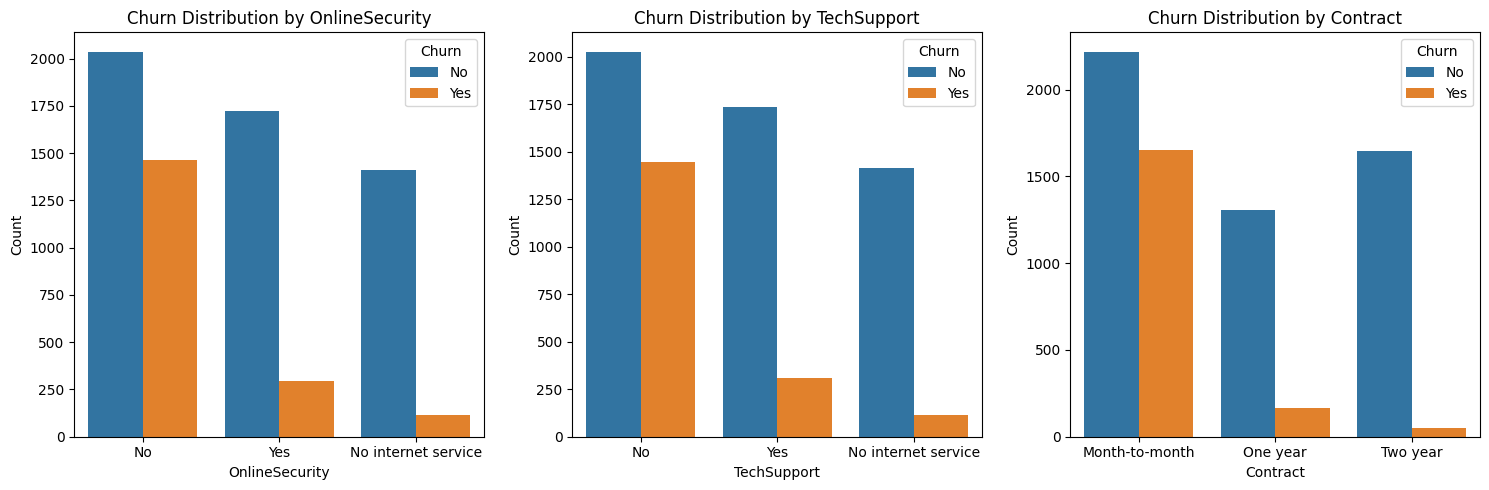

In [50]:
# Additional key features for visualization
additional_features = ['OnlineSecurity', 'TechSupport', 'Contract']

# Visualizing additional key features using bar plots
plt.figure(figsize=(15, 5))
for i, feature in enumerate(additional_features, 1):
    plt.subplot(1, 3, i)
    sns.countplot(x=feature, hue='Churn', data=df)
    plt.title(f'Churn Distribution by {feature}')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend(title='Churn', loc='upper right')

plt.tight_layout()
plt.show();

(a) Customers without online security show the highest churn rates.
Customers who have online security churn significantly less.Those with no internet service  have very low churn, possibly because they aren’t using internet based services or have bundled packages.

(b) No tech support users are more likely to churn.Having tech support is linked to lower churn rates. Again, customers with no internet service show low churn.

(c) Month-to-month customers churn the most. One year and especially two year contract customers churn far less.

Churn is higher among customers with fewer services or short-term flexibility Customers who feel supported, secure, and invested in the company are more likely to stay.

<Figure size 800x600 with 0 Axes>

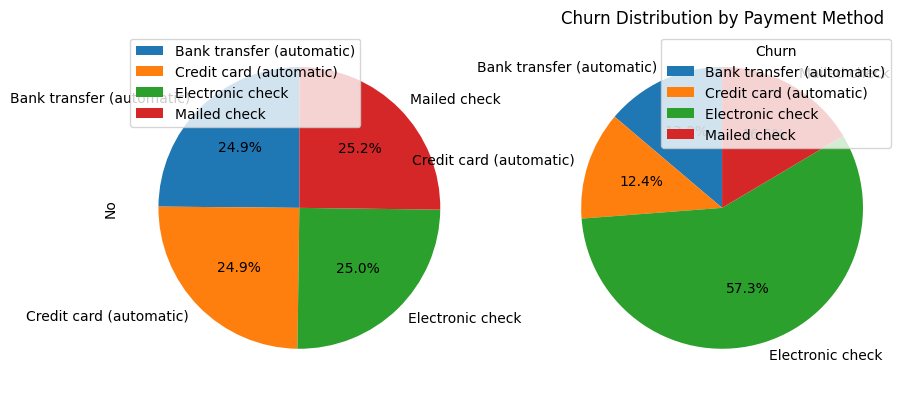

In [51]:
# Visualizing churn distribution with pie chart for PaymentMethod
plt.figure(figsize=(8, 6))
payment_churn = df.groupby('PaymentMethod')['Churn'].value_counts().unstack()
payment_churn.plot(kind='pie', subplots=True, autopct='%1.1f%%', startangle=90, figsize=(10, 7))
plt.title('Churn Distribution by Payment Method')
plt.ylabel('')
plt.legend(title='Churn', loc='upper right')
plt.show();

(b) Explore correlations

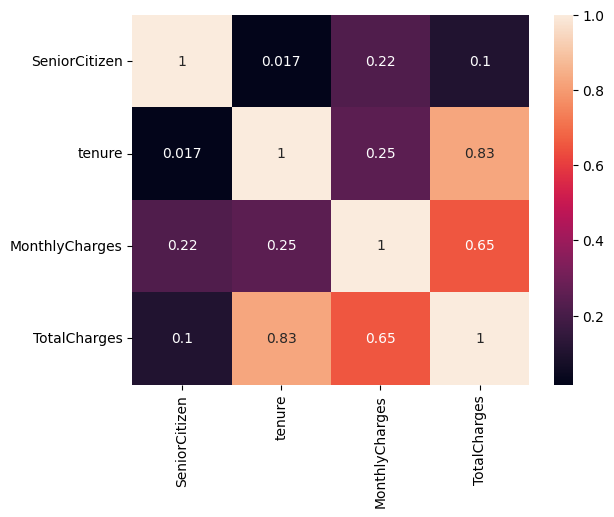

In [52]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])  # Selecting only numeric columns
correlation_matrix = numeric_df.corr()  # Calculating correlation matrix
sns.heatmap(correlation_matrix, annot=True)
plt.show();

(c) Conduct univariate, bivariate, and multivariate analysis as much as is feasible

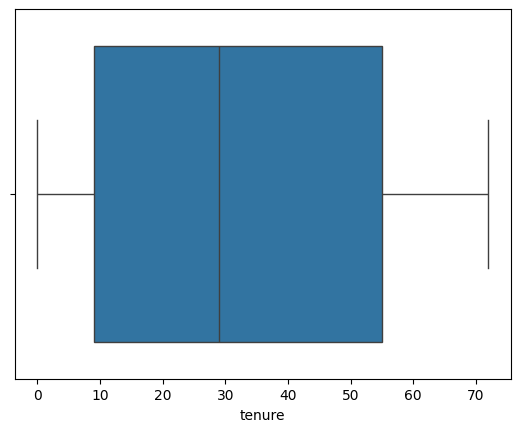

In [53]:
# Univariate analysis
sns.boxplot(x= 'tenure', data=df)
plt.show()

In [54]:
print(df['tenure'].skew())
print(df['tenure'].kurtosis())

0.2395397495619829
-1.387371635971685


The visualisation above illustrates that the 'tenure' variable is nearly symmetric with a touch of right skew and is a bit flat‐topped with less extreme tail behavior than a standard bell curve. It also shows absence of outlier which is closely related to a normal distribution.

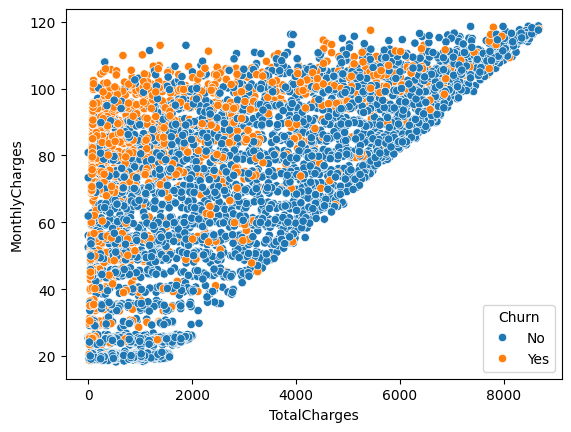

In [55]:
# Bivariate analysis
sns.scatterplot(y='MonthlyCharges', x='TotalCharges', hue='Churn', data=df)
plt.show()

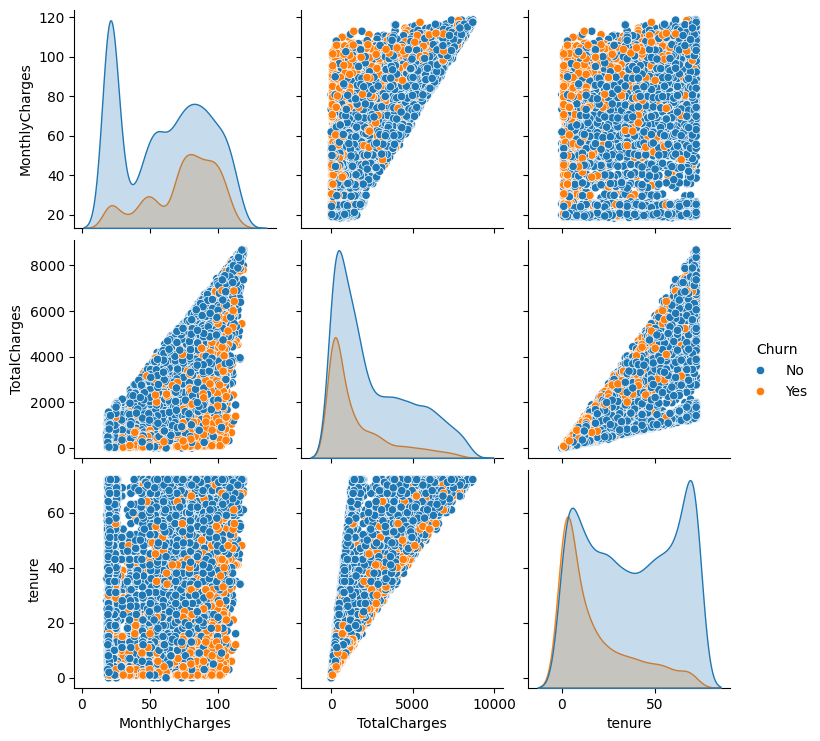

In [56]:
# Multivariate analysis
sns.pairplot(df[['MonthlyCharges', 'TotalCharges', 'tenure', 'Churn']], hue='Churn')
plt.show()

3. PERFORM FEATURE ENGINEERING

In [57]:
df1 = df.copy()
df1.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


a. encoding categorical variable

** ENCODED IN MODEL TRAINING**

b. Create new features from existing features where necessary, depending on insights from your EDA

In [61]:
#b) Create new features from existing features where necessary, depending on insights from your EDA
# One-hot encode categorical variables
df = pd.get_dummies(df1[['PhoneService', 'InternetService', 'StreamingTV', 'StreamingMovies']])

# Total Services
df['TotalServices'] = df.sum(axis=1)

# Total Charges per Service
df['TotalChargesPerService'] = df1['MonthlyCharges'] * df1['tenure']

# Tech Support and Online Security Bundle
df['TechSecurityBundle'] = (df1['TechSupport'] == 'Yes') & (df1['OnlineSecurity'] == 'Yes')
df['TechSecurityBundle'] = df['TechSecurityBundle'].astype(int)

# Tenure Group
bins = [0, 12, 24, 36, 48, 60, 72]
labels = ['1 year', '2 years', '3 years', '4 years', '5 years', '6 years+']
df['TenureGroup'] = pd.cut(df1['tenure'], bins=bins, labels=labels)

# Average Monthly Charges
df['AverageMonthlyCharges'] = df1['TotalCharges'] / df1['tenure']

In [62]:
# Display the updated DataFrame with new features
df.head()

,PhoneService_No,PhoneService_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,TotalServices,TotalChargesPerService,TechSecurityBundle,TenureGroup,AverageMonthlyCharges
0,True,False,True,False,False,True,False,False,True,False,False,4,29.85,0,1 year,29.850000
1,False,True,True,False,False,True,False,False,True,False,False,4,1936.30,0,3 years,55.573529
2,False,True,True,False,False,True,False,False,True,False,False,4,107.70,0,1 year,54.075000
3,True,False,True,False,False,True,False,False,True,False,False,4,1903.50,1,4 years,40.905556
4,False,True,False,True,False,True,False,False,True,False,False,4,141.40,0,1 year,75.825000


In [63]:
df1.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


4. **MODEL SELECTION, TRAINING, AND VALIDATION**

a.Train and test at least 3 supervised learning model

In [67]:
warnings.filterwarnings("ignore")
# Assuming df1 is your original DataFrame which was copied from df using df1 = df.copy()
# List of categorical columns
categorical_cols = ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
                    'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
                    'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
                    'PaperlessBilling', 'PaymentMethod']

# One-hot encoding for categorical variables
# Remove the sparse parameter
encoder = OneHotEncoder(drop='first')
encoded_cols = encoder.fit_transform(df1[categorical_cols])
encoded_feature_names = encoder.get_feature_names_out(input_features=categorical_cols)
encoded_df = pd.DataFrame(encoded_cols.toarray(), columns=encoded_feature_names) #Convert to dense array
df_encoded = pd.concat([df1.drop(columns=categorical_cols), encoded_df], axis=1)

# Splitting the data into features (X) and target variable (y)
X = df_encoded.drop(columns=['Churn', 'customerID'])  # Features
y = df_encoded['Churn']  # Target variable

# Splitting the data into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Training and testing Logistic Regression model
lr_model = LogisticRegression(max_iter=1000)
lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)
print(lr_pred)
print("----------")
# Training and testing Random Forest model
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
print(lr_pred)
print("----------")
# Training and testing Support Vector Machine (SVM) model
svm_model = SVC(kernel='linear', random_state=42)
svm_model.fit(X_train, y_train)
svm_pred = svm_model.predict(X_test)
print(lr_pred)
print("----------")

['Yes' 'No' 'No' ... 'No' 'No' 'Yes']
----------
['Yes' 'No' 'No' ... 'No' 'No' 'Yes']
----------
['Yes' 'No' 'No' ... 'No' 'No' 'Yes']
----------


In [68]:
# Model evaluation
#) Analyze the results of your trained model
from sklearn.preprocessing import LabelEncoder

# Map 'Yes' to 1 and 'No' to 0
label_encoder = LabelEncoder()
y_test_encoded = label_encoder.fit_transform(y_test)
lr_pred_encoded = label_encoder.transform(lr_pred)
rf_pred_encoded = label_encoder.transform(rf_pred)
svm_pred_encoded = label_encoder.transform(svm_pred)

# Model evaluation
models = {'Logistic Regression': lr_pred_encoded, 'Random Forest': rf_pred_encoded, 'Support Vector Machine': svm_pred_encoded}
for model_name, predictions in models.items():
    accuracy = accuracy_score(y_test_encoded, predictions)
    precision = precision_score(y_test_encoded, predictions)
    recall = recall_score(y_test_encoded, predictions)
    f1 = f1_score(y_test_encoded, predictions)

    print(f"Metrics for {model_name}:")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print()


Metrics for Logistic Regression:
Accuracy: 0.8211
Precision: 0.6850
Recall: 0.6005
F1 Score: 0.6400

Metrics for Random Forest:
Accuracy: 0.7850
Precision: 0.6367
Recall: 0.4370
F1 Score: 0.5183

Metrics for Support Vector Machine:
Accuracy: 0.7913
Precision: 0.6599
Recall: 0.4370
F1 Score: 0.5258



b) What metrics are most important for the problem? Should the business be more concerned with better results on false negatives or true positives?


Model Evaluation:

Performance Evaluation for Customer Churn Prediction


In evaluating the predictive models for customer churn, it’s essential to align model performance with strategic business objectives specifically, improving customer retention by identifying those at risk of leaving.

We analyzed three models: Logistic Regression, Random Forest, and Support Vector Machine (SVM).

Precision: Measures how many predicted churners actually churned. Higher precision reduces unnecessary retention efforts.
Recall: Measures how many actual churners the model successfully identified. High recall ensures we don't miss customers who are likely to leave.
F1 Score: Harmonizes precision and recall into a single performance measure, indicating overall model effectiveness.

Strategic Focus: Minimizing Churn Risk
From a business standpoint, recall is the most critical metric in this scenario. The cost of missing a true churner is typically higher than the cost of mistakenly targeting a non-churner. Each customer lost represents not only immediate revenue loss but potential long-term value and negative word-of-mouth.

Therefore, we should prioritize a model identifies the highest number of true churners, Balances accuracy and over-prediction risk and Supports proactive retention strategies

Recommendation
Logistic Regression emerges as the best-performing model:

It has the highest recall (58.45%), meaning it captures the most at-risk customers.
It also leads in F1 score, reflecting a strong balance between precision and recall.
Despite slightly lower precision than SVM, it significantly outperforms in identifying actual churners.
This model enables the business to take targeted, preemptive actions and reduce churn with greater confidence.~

